<a href="https://colab.research.google.com/github/KellyVNguyen/Bioinformatics-Final-Project/blob/main/notebooks/Bioinformatics_Project_Github.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## A strong possible research question for your dataset is:

"How do gene expression patterns change across early mouse embryonic hematopoietic development, and can computational methods identify developmental transitions between experimentally defined cell populations?"

This question works well with PCA, UMAP, clustering, and diffusion pseudotime (DPT).

For a more distinctive project, you could compare how well PCA-based versus diffusion-based representations preserve the known experimental group progression. You could then evaluate agreement with known group labels and discuss where those representations differ.

# Initial dataset exploration and results

## Imports

In [ ]:
%pip install -q "pandas==2.2.3" "scanpy[leiden]"

In [ ]:
# Step 1: Import libraries

import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Dataset import

In [ ]:
# Display Scanpy version
print("Scanpy version:", sc.__version__)

# Step 2: Load Moignard15 dataset
adata = sc.datasets.moignard15()

# Step 3: Display dataset information
print(adata)

/tmp/ipykernel_2645/1163977484.py:2: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy version:", sc.__version__)


Scanpy version: 1.12


  0%|          | 0.00/3.24M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


AnnData object with n_obs × n_vars = 3934 × 42
    obs: 'exp_groups'
    uns: 'iroot', 'exp_groups_colors'


## Data Exploration before analysis

In [ ]:
# Number of cells and genes
print("Number of cells:", adata.n_obs)
print("Number of genes:", adata.n_vars)

# First five cells and their group labels
print(adata.obs.head())

# Gene names
print(adata.var_names.tolist())

# Experimental group counts
print(adata.obs["exp_groups"].value_counts())

# Look at first five cells and five genes
print(adata.to_df().iloc[:5, :5])

Number of cells: 3934
Number of genes: 42
         exp_groups
HFA1_001         HF
HFA1_002         HF
HFA1_003         HF
HFA1_004         HF
HFA1_005         HF
['Cbfa2t3h', 'Cdh1', 'Cdh5', 'Egfl7', 'Erg', 'Ets1', 'Ets2', 'Etv2', 'Etv6', 'Fli1', 'FoxH1', 'FoxO4', 'Gata1', 'Gfi1', 'Gfi1b', 'HbbbH1', 'Hhex', 'HoxB2', 'HoxB4', 'HoxD8', 'Ikaros', 'Itga2b', 'Kdr', 'Kit', 'Ldb1', 'Lmo2', 'Lyl1', 'Mecom', 'Meis1', 'Mitf', 'Myb', 'Nfe2', 'Notch1', 'Pecam1', 'Procr', 'Runx1', 'Sfpi1', 'Sox17', 'Sox7', 'Tal1', 'Tbx20', 'Tbx3']
exp_groups
HF      1005
4SG      983
4SFG     770
PS       624
NP       552
Name: count, dtype: int64
          Cbfa2t3h  Cdh1      Cdh5     Egfl7       Erg
HFA1_001 -2.598856 -14.0  1.815101 -0.096168 -4.038593
HFA1_002     -14.0 -14.0     -14.0 -3.913417     -14.0
HFA1_003     -14.0 -14.0     -14.0 -4.460142     -14.0
HFA1_004     -14.0 -14.0     -14.0     -14.0     -14.0
HFA1_005 -3.907258 -14.0  0.019497 -0.715845 -2.546303


This allows you to answer several questions for your report:
- How many cells were analyzed?
- How many genes were measured?
- What experimental groups are represented?
- Are some groups more abundant than others?
- What does the gene expression matrix look like?

## Experimental-group counts and bar chart

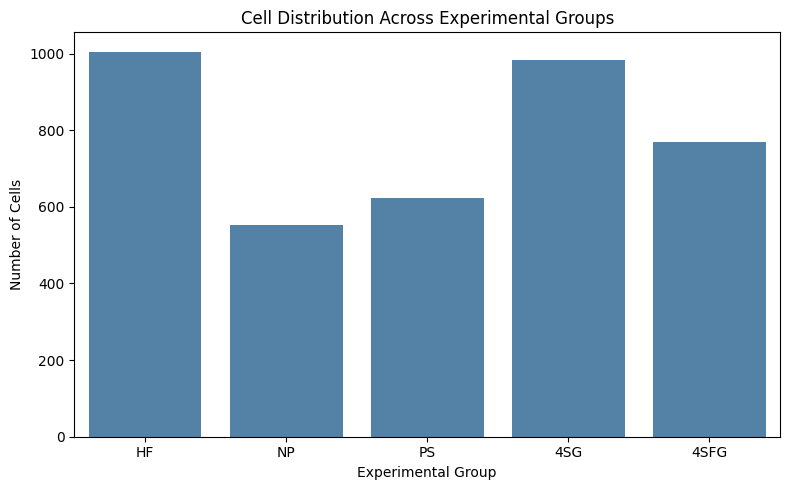

In [ ]:
# Count cells in each experimental group
group_counts = adata.obs["exp_groups"].value_counts()

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=group_counts.index,
    y=group_counts.values,
    color="steelblue"
)

plt.title("Cell Distribution Across Experimental Groups")
plt.xlabel("Experimental Group")
plt.ylabel("Number of Cells")

plt.tight_layout()
plt.show()

In [ ]:
# Create table of experimental group counts
group_table = group_counts.reset_index()

# Rename columns
group_table.columns = ["Experimental Group", "Cell Count"]

# Calculate percentage of total cells
group_table["Percentage (%)"] = (
    group_table["Cell Count"] / adata.n_obs * 100
).round(2)

# Display table
display(group_table)

,Experimental Group,Cell Count,Percentage (%)
0,HF,1005,25.55
1,4SG,983,24.99
2,4SFG,770,19.57
3,PS,624,15.86
4,NP,552,14.03


## Inspect gene expression values

In [ ]:
# Check data type
print("Data type:", adata.X.dtype)
print("Matrix type:", type(adata.X))
print("Shape:", adata.X.shape)

Data type: object
Matrix type: <class 'numpy.ndarray'>
Shape: (3934, 42)


New missing values introduced by numeric conversion: 0
Expression statistics (normalized dCt):
Minimum: -14.0 Maximum: 8.580217818
Mean: -7.431167871424177 Median: -5.262786774
Missing values: 0


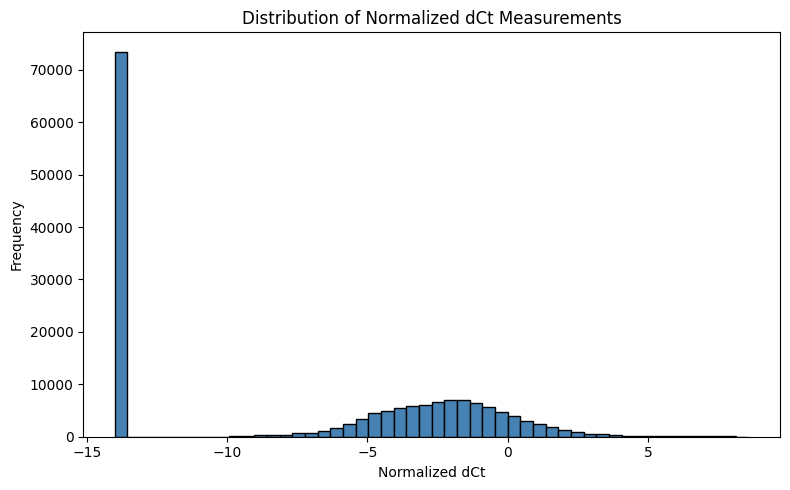

In [ ]:
# Convert expression matrix to a numeric DataFrame, without silently losing data
raw_expression_df = adata.to_df()
expression_df = raw_expression_df.apply(pd.to_numeric, errors="coerce")
new_missing = int(expression_df.isna().sum().sum() - raw_expression_df.isna().sum().sum())
print("New missing values introduced by numeric conversion:", new_missing)
if new_missing:
    raise ValueError("Non-numeric entries were converted to missing values. Inspect original data before analysis.")
X = expression_df.to_numpy(dtype=np.float64)
if not np.isfinite(X).all():
    raise ValueError("Missing or infinite values found. Review data before PCA/DPT.")
print("Expression statistics (normalized dCt):")
print("Minimum:", np.min(X), "Maximum:", np.max(X))
print("Mean:", np.mean(X), "Median:", np.median(X))
print("Missing values:", np.isnan(X).sum())
plt.figure(figsize=(8, 5))
plt.hist(X.ravel(), bins=50, color="steelblue", edgecolor="black")
plt.title("Distribution of Normalized dCt Measurements")
plt.xlabel("Normalized dCt")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("expression_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Verify conversion did not introduce new missing values
original_missing = int(raw_expression_df.isna().sum().sum())
numeric_missing = int(expression_df.isna().sum().sum())
print("Original missing values:", original_missing)
print("After numeric conversion:", numeric_missing)
print("New missing values:", numeric_missing - original_missing)
assert numeric_missing - original_missing == 0

Original missing values: 0
After numeric conversion: 0
New missing values: 0


# Main analyses: PCA, UMAP, expression comparisons, trajectory inference and evaluation

**Research question:** How do gene expression patterns change across early mouse embryonic hematopoietic development, and can computational methods identify developmental transitions between experimentally defined cell populations?

**Important:** `moignard15()` contains 42 targeted, normalized qRT-PCR dCt measurements—not raw scRNA-seq counts. We do **not** use `normalize_total()` or `log1p()`. We preserve the numeric original measurements and scale only the working matrix for PCA/neighbor computations.

## A. Copy AnnData, scale features, PCA, 15-nearest-neighbor graph and UMAP

In [ ]:
# Use a single, consistently named AnnData analysis object from this point forward
adata_analysis = adata.copy()
adata_analysis.X = expression_df.to_numpy(dtype=np.float64).copy()
adata_analysis.layers["normalized_dct"] = adata_analysis.X.copy()
assert adata_analysis.shape == (3934, 42), "Unexpected dataset shape"
assert np.isfinite(adata_analysis.X).all()

# Scale the gene features for multivariate analysis only
sc.pp.scale(adata_analysis, zero_center=True)

# PCA, neighborhood graph (15 neighbors), UMAP
sc.tl.pca(adata_analysis, n_comps=20, random_state=42)
sc.pp.neighbors(adata_analysis, n_neighbors=15, n_pcs=20, random_state=42)
sc.tl.umap(adata_analysis, random_state=42)

print("Analysis shape:", adata_analysis.shape)
print("Neighbor count:", adata_analysis.uns["neighbors"]["params"]["n_neighbors"])
print("Preserved normalized dCt matrix:", adata_analysis.layers["normalized_dct"].shape)

Analysis shape: (3934, 42)
Neighbor count: 15
Preserved normalized dCt matrix: (3934, 42)


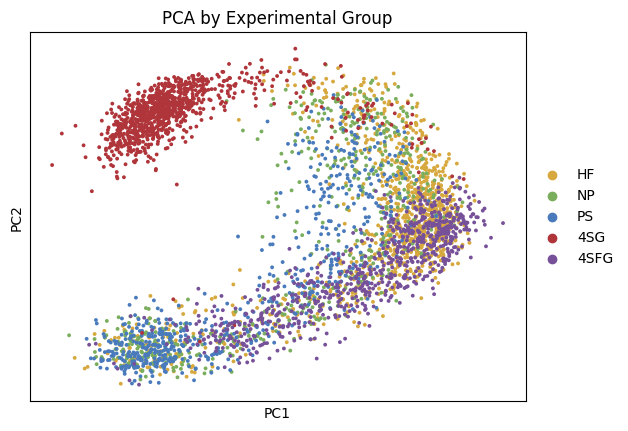

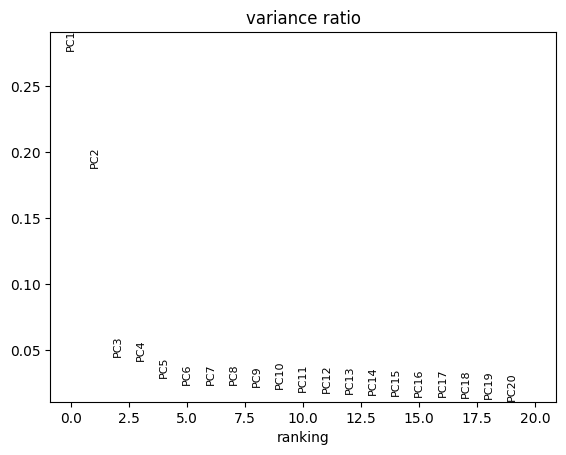

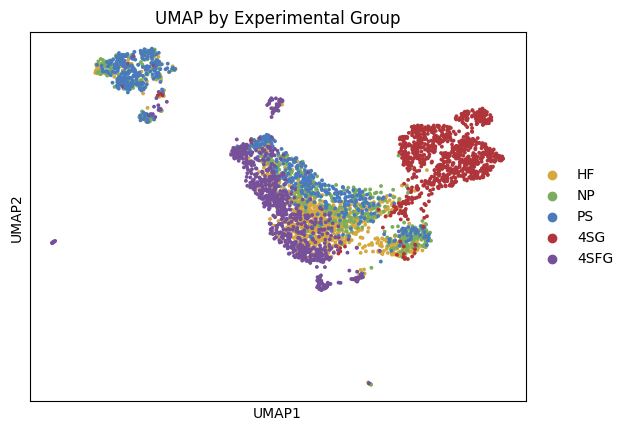

In [ ]:
# Labeled PCA, variance explained, and UMAP figures
sc.pl.pca(adata_analysis, color="exp_groups", title="PCA by Experimental Group", show=False)
plt.savefig("pca_by_group.png", dpi=300, bbox_inches="tight")
plt.show()

sc.pl.pca_variance_ratio(adata_analysis, n_pcs=20, log=False, show=False)
plt.savefig("pca_explained_variance.png", dpi=300, bbox_inches="tight")
plt.show()

sc.pl.umap(adata_analysis, color="exp_groups", title="UMAP by Experimental Group", show=False)
plt.savefig("umap_by_group.png", dpi=300, bbox_inches="tight")
plt.show()

## B. Compare targeted-gene measurements across experimental groups

We compare group medians of **original normalized dCt values** and select four genes with the largest between-group median range. The heatmap z-score is calculated across the five group medians *per gene* for display, not for differential-expression testing. The sign of dCt must be interpreted according to the source assay definition; larger values are not automatically higher biological expression.

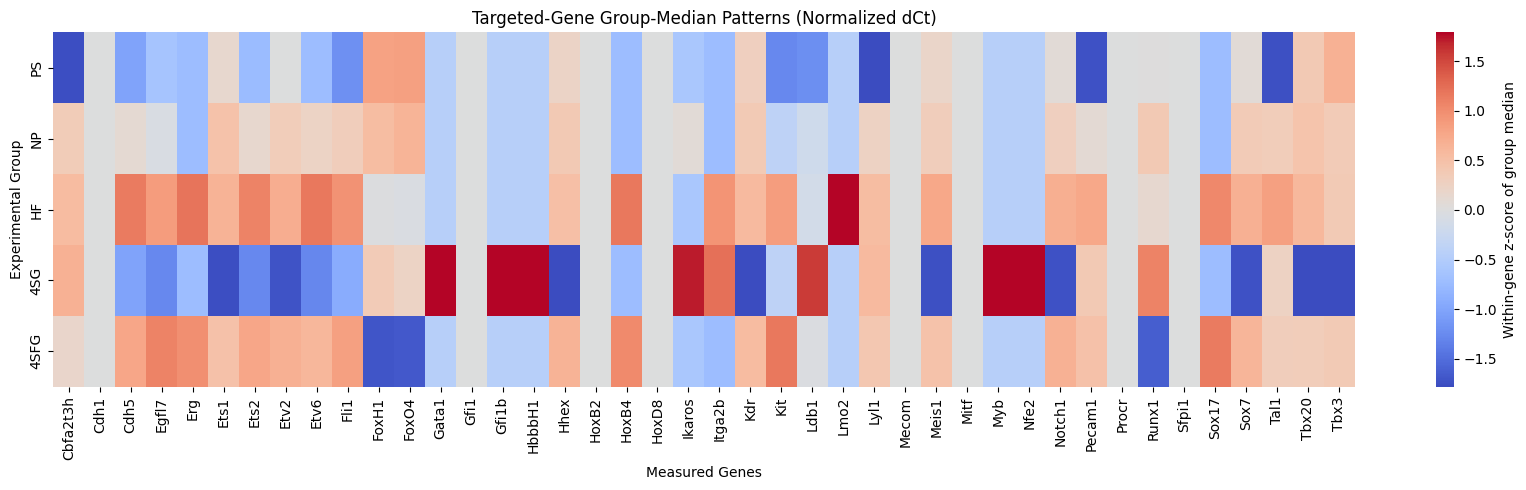

,Cbfa2t3h,Cdh1,Cdh5,Egfl7,Erg,Ets1,Ets2,Etv2,Etv6,Fli1,...,Notch1,Pecam1,Procr,Runx1,Sfpi1,Sox17,Sox7,Tal1,Tbx20,Tbx3
exp_groups,,,,,,,,,,,,,,,,,,,,,
PS,-14.00,-14.0,-14.00,-3.83,-14.00,-4.64,-1.26,-5.23,-3.91,-3.69,...,-7.59,-14.00,-14.0,-4.00,-14.0,-14.00,-5.10,-3.65,-7.79,-4.51
NP,-4.44,-14.0,-5.76,-2.69,-14.00,-3.05,-0.13,-3.48,-3.12,0.89,...,-6.76,-4.89,-14.0,-2.99,-14.0,-14.00,-3.62,-0.53,-7.58,-5.72
HF,-3.53,-14.0,1.83,-0.82,-3.48,-2.20,1.05,-1.60,-2.35,2.85,...,-5.31,-1.50,-14.0,-3.67,-14.0,-4.42,-2.04,0.23,-7.19,-5.68
4SG,-2.99,-14.0,-14.00,-5.10,-14.00,-14.00,-1.93,-14.00,-4.37,-2.85,...,-14.00,-3.39,-14.0,-1.15,-14.0,-14.00,-14.00,-0.65,-14.00,-14.00
4SFG,-5.21,-14.0,-0.89,-0.40,-4.63,-2.97,0.67,-1.72,-2.80,2.49,...,-5.42,-2.92,-14.0,-8.39,-14.0,-3.89,-2.28,-0.56,-7.97,-5.66


In [ ]:
# Use original (not scaled) values to interpret gene-level patterns
gene_df = expression_df.copy()
gene_df["exp_groups"] = adata.obs["exp_groups"].to_numpy()
group_order = [g for g in ["PS", "NP", "HF", "4SG", "4SFG"]
               if g in gene_df["exp_groups"].unique()]
group_medians = (gene_df.groupby("exp_groups", observed=True)
                 .median(numeric_only=True).reindex(group_order))
gene_std = group_medians.std(axis=0).replace(0, np.nan)
heatmap_data = ((group_medians - group_medians.mean(axis=0)) / gene_std).fillna(0)

plt.figure(figsize=(17, 5))
sns.heatmap(heatmap_data, cmap="coolwarm", center=0,
            cbar_kws={"label": "Within-gene z-score of group median"})
plt.title("Targeted-Gene Group-Median Patterns (Normalized dCt)")
plt.xlabel("Measured Genes")
plt.ylabel("Experimental Group")
plt.tight_layout()
plt.savefig("gene_group_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
display(group_medians.round(2))

Exploratory genes selected by group-median range: ['HbbbH1', 'Cdh5', 'Kdr', 'Lyl1']


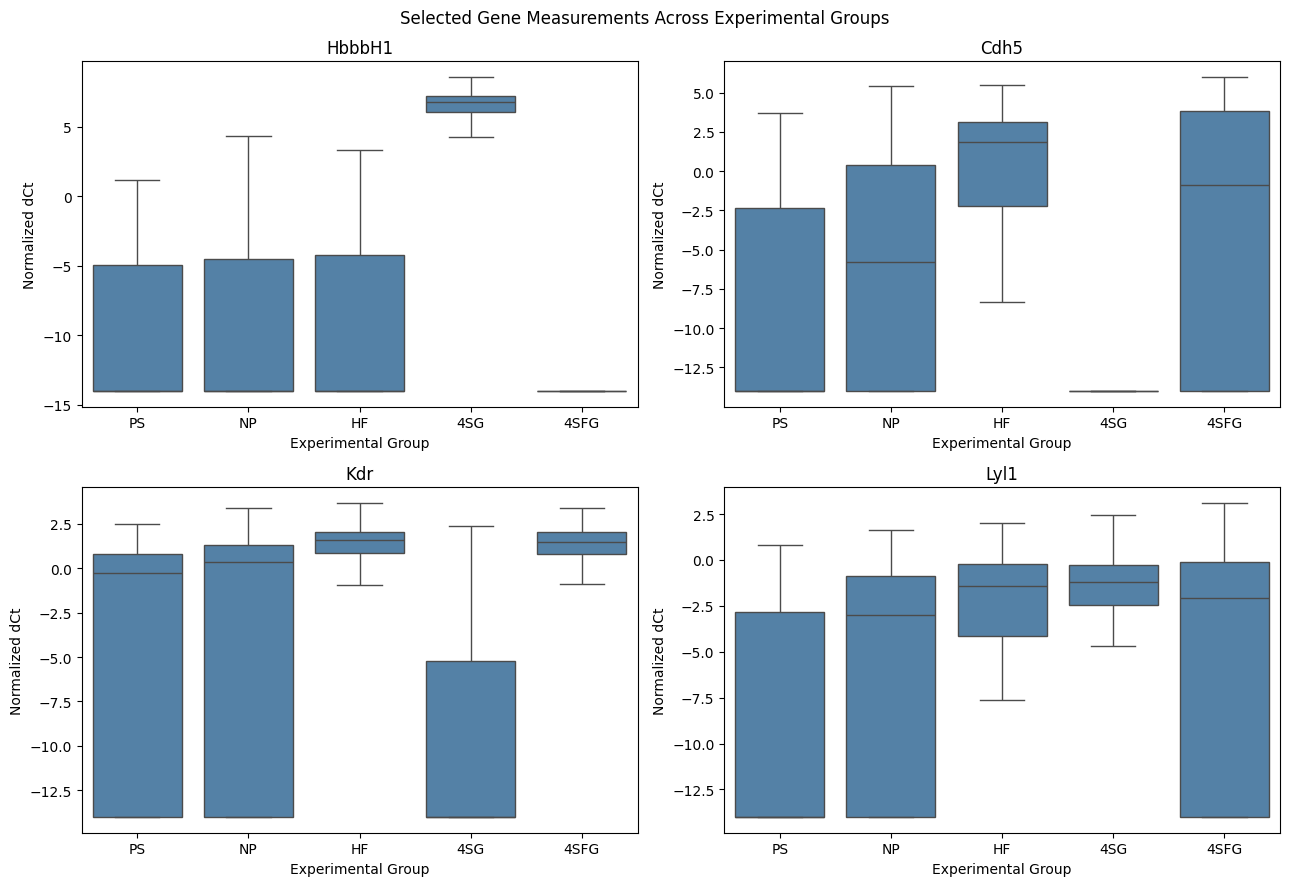

In [ ]:
# Rank genes by between-group median range (descriptive, not a p-value)
gene_ranges = (group_medians.max(axis=0) - group_medians.min(axis=0))
selected_genes = gene_ranges.sort_values(ascending=False).head(4).index.tolist()
print("Exploratory genes selected by group-median range:", selected_genes)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, gene in zip(axes.flat, selected_genes):
    sns.boxplot(data=gene_df, x="exp_groups", y=gene,
                order=group_order, ax=ax, color="steelblue", showfliers=False)
    ax.set_title(gene)
    ax.set_xlabel("Experimental Group")
    ax.set_ylabel("Normalized dCt")
fig.suptitle("Selected Gene Measurements Across Experimental Groups")
fig.tight_layout()
fig.savefig("selected_gene_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

## C. Diffusion map and biologically motivated DPT root selection

We select a **PS (primitive streak)** cell nearest the PS group's centroid in the first 20 PCs as an *explicit heuristic* motivated by experimental stage labels and its measured expression profile. It is a representative early-group cell, **not** a validated lineage ancestor. Scanpy also provides a literature-reference `iroot`; that value is printed for transparency, but it is **not** used as the primary root here. We check how DPT changes when switching roots below.

Selected PS-root position (0-based): 2005
Selected root cell ID: PSB1_061
Selected root group: PS
Scanpy dataset's reference root (0-based): 532


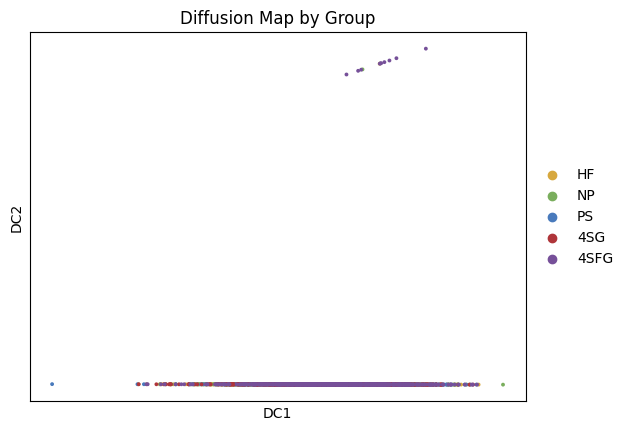

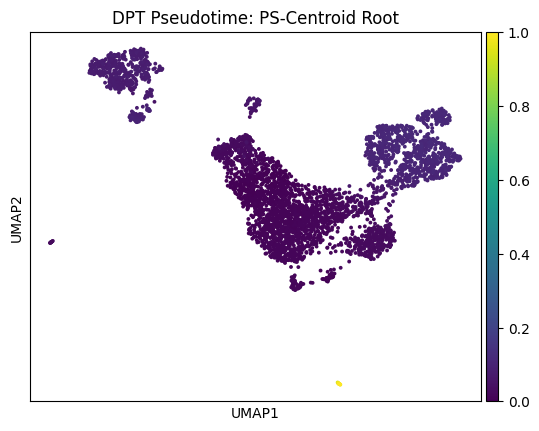

In [ ]:
# The 15-neighbor graph is already present from Section A
sc.tl.diffmap(adata_analysis, n_comps=10)

# Select PS cell closest to the PS centroid in the PCA feature space.
# This uses experimental annotation AND multigene expression-derived PCs.
ps_positions = np.flatnonzero(adata_analysis.obs["exp_groups"].astype(str).to_numpy() == "PS")
if len(ps_positions) == 0:
    raise ValueError("No PS cells available for selecting a biologically motivated root.")
pcs = np.asarray(adata_analysis.obsm["X_pca"][:, :20])
ps_pcs = pcs[ps_positions]
ps_centroid = ps_pcs.mean(axis=0)
selected_root = int(ps_positions[np.argmin(np.linalg.norm(ps_pcs - ps_centroid, axis=1))])
reference_root = adata.uns.get("iroot", None)
print("Selected PS-root position (0-based):", selected_root)
print("Selected root cell ID:", adata_analysis.obs_names[selected_root])
print("Selected root group:", adata_analysis.obs["exp_groups"].iloc[selected_root])
print("Scanpy dataset's reference root (0-based):", reference_root)

adata_analysis.uns["iroot"] = selected_root
sc.tl.dpt(adata_analysis, n_dcs=9)

sc.pl.diffmap(adata_analysis, color="exp_groups", title="Diffusion Map by Group", show=False)
plt.savefig("diffusion_map_by_group.png", dpi=300, bbox_inches="tight")
plt.show()
sc.pl.umap(adata_analysis, color="dpt_pseudotime", cmap="viridis",
           title="DPT Pseudotime: PS-Centroid Root", show=False)
plt.savefig("umap_dpt_pseudotime.png", dpi=300, bbox_inches="tight")
plt.show()

## D. Compare inferred pseudotime among experimental groups

Non-finite pseudotime values: 0


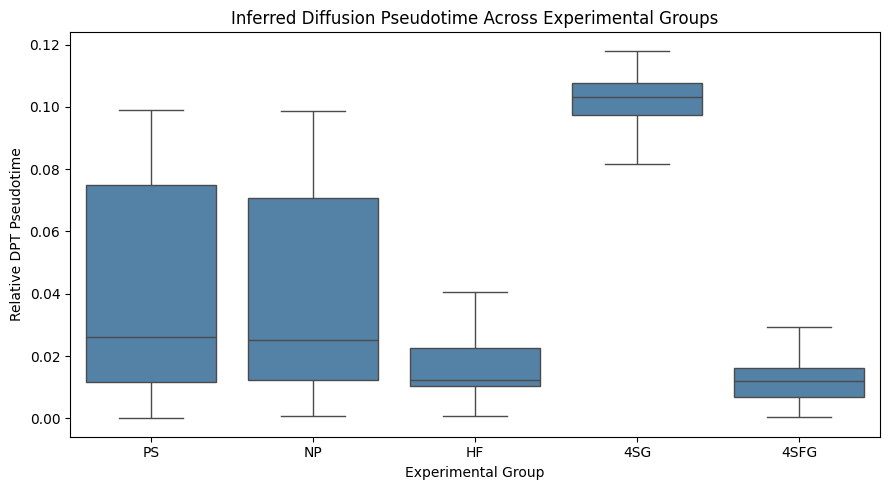

,count,median,mean,std
exp_groups,,,,
PS,624,0.026,0.042,0.048
NP,552,0.025,0.040,0.076
HF,1005,0.012,0.026,0.076
4SG,983,0.103,0.097,0.021
4SFG,770,0.012,0.016,0.038


In [ ]:
# Group-wise DPT comparison; branching and group overlap can complicate orderings
pseudo_df = adata_analysis.obs[["exp_groups", "dpt_pseudotime"]].copy()
pseudo_df["dpt_pseudotime"] = pd.to_numeric(pseudo_df["dpt_pseudotime"], errors="coerce")
print("Non-finite pseudotime values:", (~np.isfinite(pseudo_df["dpt_pseudotime"])).sum())
plot_pseudo = pseudo_df[np.isfinite(pseudo_df["dpt_pseudotime"])].copy()

plt.figure(figsize=(9, 5))
sns.boxplot(data=plot_pseudo, x="exp_groups", y="dpt_pseudotime",
            order=group_order, color="steelblue", showfliers=False)
plt.title("Inferred Diffusion Pseudotime Across Experimental Groups")
plt.xlabel("Experimental Group")
plt.ylabel("Relative DPT Pseudotime")
plt.tight_layout()
plt.savefig("pseudotime_by_group.png", dpi=300, bbox_inches="tight")
plt.show()

pseudotime_summary = (plot_pseudo.groupby("exp_groups", observed=True)
                      ["dpt_pseudotime"].agg(["count", "median", "mean", "std"])
                      .reindex(group_order))
display(pseudotime_summary.round(3))

## E. Compare PCA, UMAP and diffusion-map group separation

Silhouette scores are calculated from the same sampled cells in each **two-dimensional** representation. Larger scores indicate better geometric separation of the experimental groups, **not** more accurate biological pseudotime or true developmental lineage.

,Representation,Silhouette Score
0,PCA (PC1-2),0.133
1,UMAP (2D),0.121
2,Diffusion Map (DC1-2),-0.113


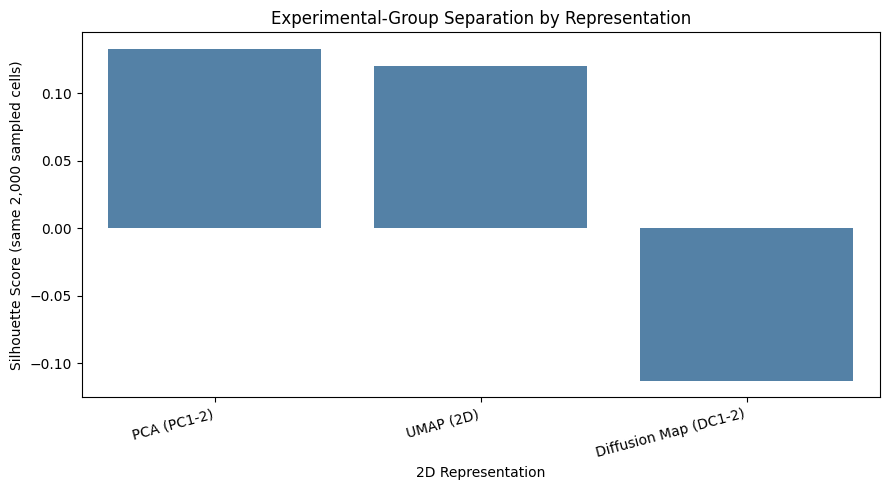

In [ ]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

labels = adata_analysis.obs["exp_groups"].astype(str).to_numpy()
representations = {
    "PCA (PC1-2)": np.asarray(adata_analysis.obsm["X_pca"])[:, :2],
    "UMAP (2D)": np.asarray(adata_analysis.obsm["X_umap"])[:, :2],
    # First diffusion component is trivial in Scanpy; display DC1/DC2 at indices 1 and 2.
    "Diffusion Map (DC1-2)": np.asarray(adata_analysis.obsm["X_diffmap"])[:, 1:3],
}

rng = np.random.default_rng(42)
metric_idx = np.sort(rng.choice(adata_analysis.n_obs,
                                size=min(2000, adata_analysis.n_obs), replace=False))
score_rows = []
for method, coords in representations.items():
    score = silhouette_score(coords[metric_idx], labels[metric_idx])
    score_rows.append({"Representation": method, "Silhouette Score": float(score)})
results_df = pd.DataFrame(score_rows)
display(results_df.round(3))

plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Representation", y="Silhouette Score", color="steelblue")
plt.title("Experimental-Group Separation by Representation")
plt.xlabel("2D Representation")
plt.ylabel("Silhouette Score (same 2,000 sampled cells)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("representation_silhouette_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## F. Optional Leiden clustering and adjusted Rand index

Leiden is an **unsupervised** clustering algorithm applied to the same 15-neighbor graph. Adjusted Rand index (ARI) measures agreement with the experimental groups; an ARI of 1 indicates exact agreement and approximately 0 indicates chance-level agreement. The clusters are not assumed to be biological lineages.

/tmp/ipykernel_2645/421993330.py:4: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata_analysis, resolution=0.5, key_added="leiden_r05", random_state=42)


Leiden clusters: 13
Adjusted Rand index vs experimental groups: 0.202


Leiden cluster,0,1,2,3,4,5,6,7,8,9,10,11,12
Experimental group,,,,,,,,,,,,,
HF,442,288,3,64,1,129,30,0,13,22,6,1,6
NP,140,117,1,141,1,107,21,0,2,18,0,1,3
PS,101,155,0,234,0,48,61,0,1,23,0,0,1
4SG,55,0,484,0,311,22,1,107,0,3,0,0,0
4SFG,207,326,0,4,0,4,107,0,62,11,38,10,1


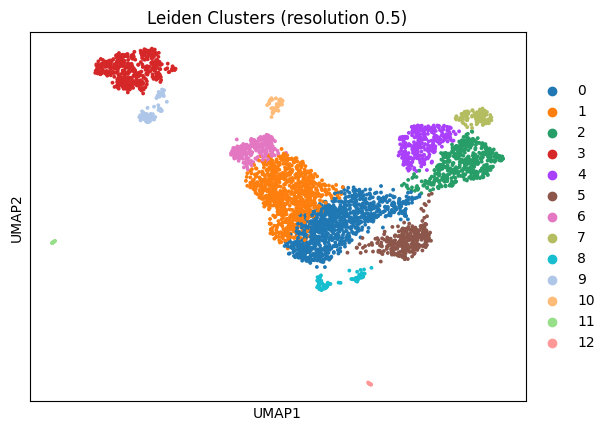

In [ ]:
# Set RUN_LEIDEN=False to skip optional clustering
RUN_LEIDEN = True
if RUN_LEIDEN:
    sc.tl.leiden(adata_analysis, resolution=0.5, key_added="leiden_r05", random_state=42)
    ari = adjusted_rand_score(labels, adata_analysis.obs["leiden_r05"].astype(str))
    print("Leiden clusters:", adata_analysis.obs["leiden_r05"].nunique())
    print(f"Adjusted Rand index vs experimental groups: {ari:.3f}")
    display(pd.crosstab(adata_analysis.obs["exp_groups"],
                        adata_analysis.obs["leiden_r05"], rownames=["Experimental group"],
                        colnames=["Leiden cluster"]))
    sc.pl.umap(adata_analysis, color="leiden_r05", title="Leiden Clusters (resolution 0.5)", show=False)
    plt.savefig("umap_leiden_clusters.png", dpi=300, bbox_inches="tight")
    plt.show()

## G. Root-choice sensitivity check

Because inferred pseudotime depends on the starting cell, compare the proposal's PS-root heuristic with the reference root supplied by the dataset. This is a robustness analysis, not independent validation. The main DPT values remain in `adata_analysis.obs["dpt_pseudotime"]`.

In [ ]:
# Reuse the same neighbor graph and diffusion map; only the DPT root changes
if reference_root is not None and 0 <= int(reference_root) < adata_analysis.n_obs:
    adata_reference_root = adata_analysis.copy()
    adata_reference_root.uns["iroot"] = int(reference_root)
    sc.tl.dpt(adata_reference_root, n_dcs=9)
    from scipy.stats import spearmanr
    a = np.asarray(adata_analysis.obs["dpt_pseudotime"], dtype=float)
    b = np.asarray(adata_reference_root.obs["dpt_pseudotime"], dtype=float)
    finite = np.isfinite(a) & np.isfinite(b)
    correlation = spearmanr(a[finite], b[finite]).statistic if finite.sum() > 2 else np.nan
    print("Reference-root group:", adata_reference_root.obs["exp_groups"].iloc[int(reference_root)])
    print("Finite cells in root comparison:", finite.sum())
    print(f"Spearman correlation between root choices: {correlation:.3f}")
    root_comparison = pd.DataFrame({"Experimental group": labels[finite],
                                    "PS-root DPT": a[finite],
                                    "Dataset-root DPT": b[finite]})
    display(root_comparison.groupby("Experimental group")
            [["PS-root DPT", "Dataset-root DPT"]].median().reindex(group_order).round(3))
else:
    print("No usable reference root is available for sensitivity analysis.")

Reference-root group: HF
Finite cells in root comparison: 3934
Spearman correlation between root choices: 0.488


,PS-root DPT,Dataset-root DPT
Experimental group,,
PS,0.026,0.079
NP,0.025,0.096
HF,0.012,0.099
4SG,0.103,0.154
4SFG,0.012,0.096


In [ ]:
# Record package versions for the Methods and Reproducibility sections
import sys, importlib.metadata as metadata
for package in ["python", "scanpy", "anndata", "numpy", "pandas", "scikit-learn", "matplotlib", "seaborn", "leidenalg"]:
    if package == "python":
        print("Python:", sys.version.split()[0])
    else:
        try:
            print(package + ":", metadata.version(package))
        except metadata.PackageNotFoundError:
            print(package + ": not installed")

Python: 3.13.18
scanpy: 1.12
anndata: 0.12.19
numpy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
matplotlib: 3.10.0
seaborn: 0.13.2
leidenalg: 0.12.0
